# EN4554 Assignment 2 — Convolutional Neural Networks

**Name:** _your name_
**Index number:** _your index_
**GitHub repository:** _link_

**Use of AI tools.** Claude (Anthropic) was used to help write and structure the code in this notebook.
All code was read, run and checked by me, and the interpretation of the results is my own.

**How to run.** Runtime → GPU (Colab T4). Run all cells top to bottom. Every finished experiment is cached as JSON in
`results/` (figures in `figs/`), so after a disconnect re-running the notebook skips completed runs.
Set `QUICK = True` for a few-minute smoke test (numbers meaningless); set `FORCE_RERUN = True` to ignore the cache.

## Setup

In [ ]:

# Colab: keep results and figures on Google Drive so a disconnect does not lose finished runs.
import os
try:
    from google.colab import drive
    drive.mount('/content/drive')
    WORK_DIR = '/content/drive/MyDrive/en4554_a2'
    os.makedirs(WORK_DIR, exist_ok=True)
    os.chdir(WORK_DIR)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print('working directory:', os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
working directory: /content/drive/MyDrive/en4554_a2


In [ ]:
import os, json, time, math, random, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

QUICK = False        # True: tiny smoke test (few epochs, small data)
FORCE_RERUN = False  # True: ignore cached results in RES_DIR
SEED = 0

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = device.type == 'cuda'          # mixed precision on the GPU (Tasks 3-4)
torch.backends.cudnn.benchmark = True

DATA_DIR = './data'
FIG_DIR = './figs_quick' if QUICK else './figs'
RES_DIR = './results_quick' if QUICK else './results'
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)

plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
print('torch', torch.__version__, '| device:', device,
      '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU')


def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def E(n):
    """Number of epochs (scaled down in QUICK mode)."""
    return max(1, n // 10) if QUICK else n


def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name + '.png'), dpi=150, bbox_inches='tight')


def run_or_load(key, fn):
    """Run fn() once and cache its (JSON-serialisable) result under RES_DIR/key.json."""
    path = os.path.join(RES_DIR, key.replace(' ', '_').replace('/', '-') + '.json')
    if os.path.exists(path) and not FORCE_RERUN:
        with open(path) as f:
            return json.load(f)
    out = fn()
    with open(path, 'w') as f:
        json.dump(out, f)
    return out


def smooth(v, k=50):
    v = np.asarray(v, dtype=float)
    k = max(1, min(k, len(v)))
    return np.convolve(v, np.ones(k) / k, mode='valid')


def n_params(model):
    return sum(p.numel() for p in model.parameters())

torch 2.11.0+cu130 | device: cuda | Tesla T4


### Data
CIFAR-10 training set → 45k train / 5k validation (fixed random split). Per-channel mean/std are computed on the
45k training images only and used to normalise all splits. The whole dataset is kept as a tensor on the GPU and
augmentation is done batch-wise on the GPU (much faster than a `DataLoader` on Colab's 2 CPU cores).
The test set is loaded only in Task 4 and used once.

100%|██████████| 170M/170M [36:41<00:00, 77.5kB/s]


train (45000, 3, 32, 32) | val (5000, 3, 32, 32)
channel mean [0.4912 0.482  0.4464] | channel std [0.2472 0.2436 0.2617]
val class counts [482, 508, 494, 504, 532, 507, 502, 506, 498, 467]


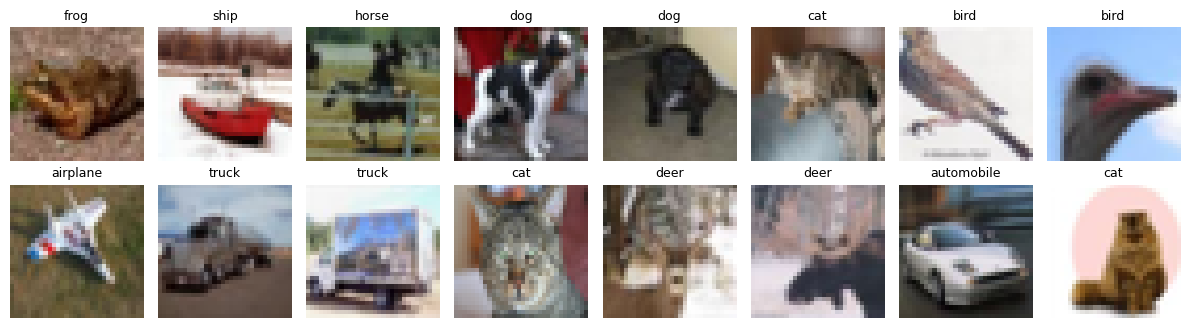

In [ ]:
set_seed(SEED)
_train = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
CLASSES = _train.classes
X_all = torch.tensor(_train.data).permute(0, 3, 1, 2).float().div_(255)   # (50000, 3, 32, 32) in [0, 1]
y_all = torch.tensor(_train.targets)

perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(SEED))
tr_idx, va_idx = perm[:45000], perm[45000:]
MEAN = X_all[tr_idx].mean(dim=(0, 2, 3))
STD = X_all[tr_idx].std(dim=(0, 2, 3))


def normalize(x):
    return (x - MEAN.view(1, 3, 1, 1)) / STD.view(1, 3, 1, 1)


Xtr, ytr = normalize(X_all[tr_idx]).to(device), y_all[tr_idx].to(device)
Xva, yva = normalize(X_all[va_idx]).to(device), y_all[va_idx].to(device)
if QUICK:
    Xtr, ytr, Xva, yva = Xtr[:2000], ytr[:2000], Xva[:500], yva[:500]

print('train', tuple(Xtr.shape), '| val', tuple(Xva.shape))
print('channel mean', MEAN.numpy().round(4), '| channel std', STD.numpy().round(4))
print('val class counts', torch.bincount(yva.cpu(), minlength=10).tolist())

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_all[tr_idx[i]].permute(1, 2, 0)); ax.set_title(CLASSES[y_all[tr_idx[i]]], fontsize=9); ax.axis('off')
plt.tight_layout(); savefig('data_samples'); plt.show()
del X_all

### Shared training utilities
GPU augmentations (random flip, random crop with 4-pixel zero padding, **cutout** and **mixup** — implemented here),
a mini-batch iterator, `evaluate`, and a generic `train` loop used from Task 2(c) on.

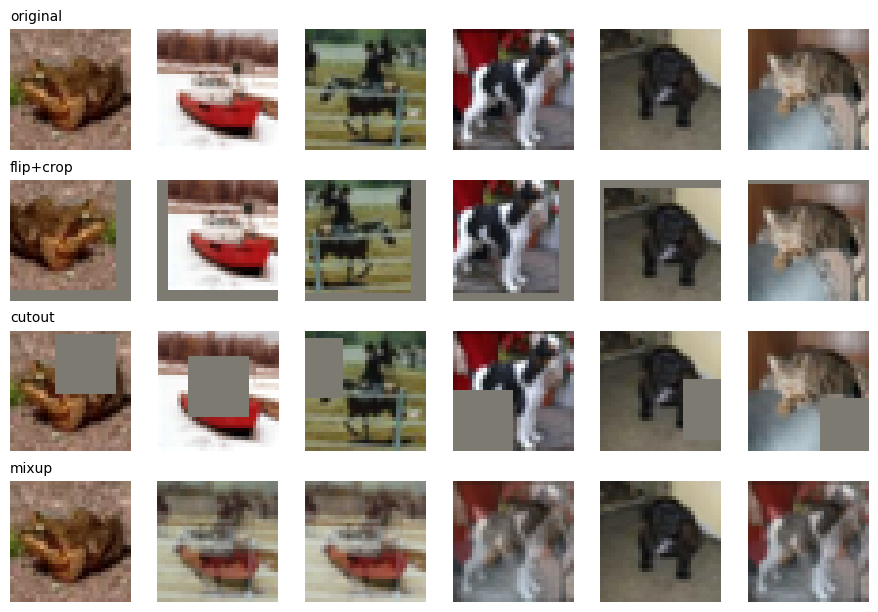

In [ ]:
def iterate(X, y, bs, shuffle=True):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), bs):
        j = idx[i:i + bs]
        yield X[j], y[j]


def random_flip(x):
    m = torch.rand(x.size(0), device=x.device) < 0.5
    return torch.where(m[:, None, None, None], x.flip(3), x)


def random_crop(x, pad=4):
    """Zero-pad by `pad` (zero = mean pixel after normalisation) and take a random 32x32 crop per image."""
    B, C, H, W = x.shape
    xp = F.pad(x, (pad, pad, pad, pad))
    i = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    j = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    rows = i[:, None] + torch.arange(H, device=x.device)          # (B, H)
    cols = j[:, None] + torch.arange(W, device=x.device)          # (B, W)
    b = torch.arange(B, device=x.device)[:, None, None, None]
    c = torch.arange(C, device=x.device)[None, :, None, None]
    return xp[b, c, rows[:, None, :, None], cols[:, None, None, :]]


def cutout(x, size=16):
    """Zero a size x size square at a random centre in every image (square is clipped at the border)."""
    B, C, H, W = x.shape
    cy = torch.randint(0, H, (B, 1, 1), device=x.device)
    cx = torch.randint(0, W, (B, 1, 1), device=x.device)
    ys = torch.arange(H, device=x.device).view(1, H, 1)
    xs = torch.arange(W, device=x.device).view(1, 1, W)
    mask = (ys >= cy - size // 2) & (ys < cy + size // 2) & (xs >= cx - size // 2) & (xs < cx + size // 2)
    return x.masked_fill(mask[:, None], 0.0)


def mixup(x, y, alpha):
    """x~ = lam*x_i + (1-lam)*x_j with lam ~ Beta(alpha, alpha); the loss is mixed with the same lam."""
    lam = float(np.random.beta(alpha, alpha))
    p = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[p], y, y[p], lam


def make_aug(flipcrop=False, cut=False, cut_size=16):
    if not (flipcrop or cut):
        return None
    def aug(x):
        if flipcrop:
            x = random_crop(random_flip(x))
        if cut:
            x = cutout(x, cut_size)
        return x
    return aug


# visual check of the augmentations
_x = Xtr[:6]
_rows = {'original': _x, 'flip+crop': random_crop(random_flip(_x)), 'cutout': cutout(_x),
         'mixup': mixup(_x, ytr[:6], 1.0)[0]}
fig, axes = plt.subplots(len(_rows), 6, figsize=(9, 6.2))
for r, (name, xs) in enumerate(_rows.items()):
    for c in range(6):
        img = (xs[c].cpu() * STD.view(3, 1, 1) + MEAN.view(3, 1, 1)).clamp(0, 1)
        axes[r, c].imshow(img.permute(1, 2, 0)); axes[r, c].axis('off')
    axes[r, 0].set_title(name, loc='left', fontsize=10)
plt.tight_layout(); savefig('augmentations'); plt.show()

In [ ]:
@torch.no_grad()
def evaluate(model, X, y, bs=1000, amp=False):
    model.eval()
    loss, correct = 0.0, 0
    for i in range(0, len(X), bs):
        xb, yb = X[i:i + bs], y[i:i + bs]
        with torch.autocast(device.type, dtype=torch.float16, enabled=amp):
            out = model(xb)
        loss += F.cross_entropy(out.float(), yb, reduction='sum').item()
        correct += (out.argmax(1) == yb).sum().item()
    return loss / len(X), correct / len(X)


def train(model, X, y, Xv, yv, *, epochs, make_opt, sched=None, bs=128, aug=None, mixup_alpha=0.0,
          label_smoothing=0.0, amp=False, track_train_acc=False, name='', verbose=True):
    """Generic training loop. Returns a JSON-serialisable history.
    train_loss: mean mini-batch loss of the epoch (on augmented data); train_acc: accuracy on up to 5k
    *clean* training images in eval mode; val_*: validation loss/accuracy after every epoch."""
    opt = make_opt(model.parameters())
    total = epochs * math.ceil(len(X) / bs)
    if sched == 'cosine':
        scheduler = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: 0.5 * (1 + math.cos(math.pi * s / total)))
    elif sched == 'onecycle':
        scheduler = torch.optim.lr_scheduler.OneCycleLR(
            opt, max_lr=[g['lr'] for g in opt.param_groups], total_steps=total, pct_start=0.25)
    else:
        scheduler = None
    scaler = torch.amp.GradScaler(device.type, enabled=amp)
    H = {k: [] for k in ['train_loss', 'val_loss', 'val_acc', 'train_acc', 'iter_loss']}
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        losses = []
        for xb, yb in iterate(X, y, bs):
            if aug is not None:
                xb = aug(xb)
            if mixup_alpha > 0:
                xb, ya, yb2, lam = mixup(xb, yb, mixup_alpha)
            with torch.autocast(device.type, dtype=torch.float16, enabled=amp):
                out = model(xb)
                if mixup_alpha > 0:
                    loss = lam * F.cross_entropy(out, ya, label_smoothing=label_smoothing) \
                        + (1 - lam) * F.cross_entropy(out, yb2, label_smoothing=label_smoothing)
                else:
                    loss = F.cross_entropy(out, yb, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            if scheduler is not None:
                scheduler.step()
            losses.append(loss.detach())
        losses = torch.stack(losses).float().cpu().numpy()
        H['iter_loss'] += losses.tolist()
        H['train_loss'].append(float(losses.mean()))
        if not np.isfinite(H['train_loss'][-1]):
            print(f'[{name}] diverged at epoch {ep + 1}')
            H['diverged'] = True
            vl, va = float('nan'), 0.1
        else:
            vl, va = evaluate(model, Xv, yv, amp=amp)
        H['val_loss'].append(vl); H['val_acc'].append(va)
        if track_train_acc:
            H['train_acc'].append(evaluate(model, X[:5000], y[:5000], amp=amp)[1])
        if verbose and ((ep + 1) % max(1, epochs // 5) == 0 or ep == epochs - 1 or H.get('diverged')):
            msg = f'[{name}] ep {ep + 1:3d}/{epochs}  train_loss {H["train_loss"][-1]:.4f}  val_acc {va:.4f}'
            if track_train_acc:
                msg += f'  train_acc {H["train_acc"][-1]:.4f}'
            print(msg + f'  ({time.time() - t0:.0f}s)')
        if H.get('diverged'):
            break
    H['time'] = time.time() - t0
    H['params'] = n_params(model)
    return H

---
## Task 1 — Backpropagation

### (a) Linear, ReLU and softmax cross-entropy with explicit `forward`/`backward`
No autograd: every layer caches what it needs in `forward` and returns $\partial L/\partial(\text{input})$ from `backward`.

* Linear $y = xW + b$: $\;\partial L/\partial W = x^\top g,\;\partial L/\partial b = \sum_n g_n,\;\partial L/\partial x = gW^\top$
* ReLU: $g \odot \mathbb{1}[x>0]$; Sigmoid (for part d): $g \odot \sigma(x)(1-\sigma(x))$
* Softmax cross-entropy (mean over the batch): $\partial L/\partial z = (\mathrm{softmax}(z) - \mathrm{onehot}(y))/N$

In [ ]:
class Linear:
    def __init__(self, n_in, n_out, init='he', dtype=torch.float32, device=device):
        std = math.sqrt(2.0 / n_in) if init == 'he' else math.sqrt(2.0 / (n_in + n_out))   # He / Xavier (normal)
        self.W = torch.randn(n_in, n_out, dtype=dtype, device=device) * std
        self.b = torch.zeros(n_out, dtype=dtype, device=device)
        self.params = [self.W, self.b]
        self.grads = [None, None]

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, g):                 # g = dL/d(out), shape (N, n_out)
        self.grads = [self.x.T @ g, g.sum(0)]
        return g @ self.W.T


class ReLU:
    params, grads = [], []

    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, g):
        return g * self.mask


class Sigmoid:
    params, grads = [], []

    def forward(self, x):
        self.out = torch.sigmoid(x)
        return self.out

    def backward(self, g):
        return g * self.out * (1 - self.out)


class SoftmaxCrossEntropy:
    def forward(self, z, y):
        z = z - z.max(1, keepdim=True).values                  # numerical stability
        logp = z - z.exp().sum(1, keepdim=True).log()
        self.p, self.y = logp.exp(), y
        return -logp[torch.arange(len(y)), y].mean()

    def backward(self):
        g = self.p.clone()
        g[torch.arange(len(self.y)), self.y] -= 1
        return g / len(self.y)


class MLP:
    def __init__(self, sizes, act='relu', init=None, dtype=torch.float32, device=device):
        init = init or ('he' if act == 'relu' else 'xavier')
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], init, dtype, device))
            if i < len(sizes) - 2:
                self.layers.append(ReLU() if act == 'relu' else Sigmoid())
        self.criterion = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.criterion.forward(self.forward(x), y)

    def backward(self):                     # returns dL/dx
        g = self.criterion.backward()
        for layer in reversed(self.layers):
            g = layer.backward(g)
        return g

    @property
    def linears(self):
        return [l for l in self.layers if isinstance(l, Linear)]

    @property
    def params(self):
        return [p for l in self.layers for p in l.params]

    @property
    def grads(self):
        return [g for l in self.layers for g in l.grads]

    def sgd_step(self, lr):
        for p, g in zip(self.params, self.grads):
            p -= lr * g

### (b) Gradient check against autograd and centred finite differences
Small network 20–16–16–10 in float64, batch of 8. Relative error $\;\|a-b\|_2 / (\|a\|_2 + \|b\|_2)$, plus
`torch.allclose`. Finite differences: $\;(L(\theta+\varepsilon e_i) - L(\theta-\varepsilon e_i))/2\varepsilon$ for **every** entry, $\varepsilon=10^{-6}$.

In [ ]:
def rel_err(a, b):
    return ((a - b).norm() / max((a.norm() + b.norm()).item(), 1e-30)).item()


def autograd_reference(net, x, y, act):
    """Same weights, same computation, but with torch autograd."""
    ps = [p.clone().requires_grad_(True) for p in net.params]
    xa = x.clone().requires_grad_(True)
    h = xa
    for k in range(0, len(ps), 2):
        h = h @ ps[k] + ps[k + 1]
        if k < len(ps) - 2:
            h = torch.relu(h) if act == 'relu' else torch.sigmoid(h)
    F.cross_entropy(h, y).backward()
    return [p.grad for p in ps] + [xa.grad]


def finite_diff(net, x, y, t, eps=1e-6):
    """Centred finite-difference gradient of the loss w.r.t. tensor t (perturbed in place)."""
    g = torch.zeros_like(t)
    flat, gf = t.view(-1), g.view(-1)
    for i in range(flat.numel()):
        old = flat[i].item()
        flat[i] = old + eps; lp = net.loss(x, y).item()
        flat[i] = old - eps; lm = net.loss(x, y).item()
        flat[i] = old
        gf[i] = (lp - lm) / (2 * eps)
    return g


rows = []
for act in ['relu', 'sigmoid']:
    torch.manual_seed(0)
    net = MLP([20, 16, 16, 10], act=act, dtype=torch.float64, device='cpu')
    x = torch.randn(8, 20, dtype=torch.float64); y = torch.randint(0, 10, (8,))
    net.loss(x, y); dx = net.backward()
    manual = [g.clone() for g in net.grads] + [dx]
    auto = autograd_reference(net, x, y, act)
    fd = [finite_diff(net, x, y, t) for t in net.params + [x]]
    names = [f'{n}{i + 1}' for i in range(len(net.linears)) for n in ('W', 'b')] + ['x (input)']
    for n, m, a, f in zip(names, manual, auto, fd):
        rows.append({'activation': act, 'tensor': n, 'shape': tuple(m.shape),
                     'rel. err vs autograd': rel_err(m, a), 'allclose (autograd)': torch.allclose(m, a),
                     'rel. err vs finite diff.': rel_err(m, f), 'allclose (finite diff.)': torch.allclose(m, f, rtol=1e-5, atol=1e-7)})
gradcheck_df = pd.DataFrame(rows)
pd.set_option('display.float_format', '{:.2e}'.format)
display(gradcheck_df)
json.dump(gradcheck_df.astype({'shape': str}).to_dict('records'), open(os.path.join(RES_DIR, 't1b_gradcheck.json'), 'w'))

,activation,tensor,shape,rel. err vs autograd,allclose (autograd),rel. err vs finite diff.,allclose (finite diff.)
0,relu,W1,"(20, 16)",5.94e-17,True,7.64e-10,True
1,relu,b1,"(16,)",3.90e-17,True,4.25e-10,True
2,relu,W2,"(16, 16)",4.38e-17,True,5.18e-10,True
3,relu,b2,"(16,)",6.57e-17,True,5.91e-10,True
4,relu,W3,"(16, 10)",3.41e-17,True,5.86e-10,True
5,relu,b3,"(10,)",2.02e-17,True,1.06e-09,True
6,relu,x (input),"(8, 20)",7.61e-17,True,1.26e-09,True
7,sigmoid,W1,"(20, 16)",1.12e-16,True,1.40e-08,True
8,sigmoid,b1,"(16,)",1.09e-16,True,1.18e-08,True
9,sigmoid,W2,"(16, 16)",8.95e-17,True,5.74e-09,True


> **Interpretation.** _To be written from the results._
> <!-- points to cover: autograd errors ~1e-16 (machine precision, same maths); FD ~1e-9..1e-11 (truncation O(eps^2) + round-off O(1/eps)); all allclose True -->

### (c) Training the MLP with SGD on flattened CIFAR-10
3072–512–256–10 ReLU MLP built from the layers above, plain mini-batch SGD (batch 128, constant learning rate), no autograd.

ep  1  train_loss 1.7459  val_loss 1.6286  val_acc 0.4248  (1s)
ep  2  train_loss 1.4737  val_loss 1.5615  val_acc 0.4444  (1s)
ep  3  train_loss 1.3551  val_loss 1.5348  val_acc 0.4686  (2s)
ep  4  train_loss 1.2634  val_loss 1.4831  val_acc 0.4878  (2s)
ep  5  train_loss 1.1881  val_loss 1.4934  val_acc 0.4872  (3s)
ep  6  train_loss 1.1197  val_loss 1.4649  val_acc 0.4946  (3s)
ep  7  train_loss 1.0574  val_loss 1.4942  val_acc 0.4932  (3s)
ep  8  train_loss 0.9964  val_loss 1.4670  val_acc 0.4976  (4s)
ep  9  train_loss 0.9370  val_loss 1.4712  val_acc 0.5144  (4s)
ep 10  train_loss 0.8900  val_loss 1.5267  val_acc 0.4950  (5s)
ep 11  train_loss 0.8353  val_loss 1.5550  val_acc 0.4938  (5s)
ep 12  train_loss 0.7865  val_loss 1.5601  val_acc 0.4962  (6s)
ep 13  train_loss 0.7393  val_loss 1.5900  val_acc 0.4928  (6s)
ep 14  train_loss 0.6912  val_loss 1.5827  val_acc 0.5014  (6s)
ep 15  train_loss 0.6504  val_loss 1.5952  val_acc 0.5078  (7s)
ep 16  train_loss 0.6069  val_loss 1.653

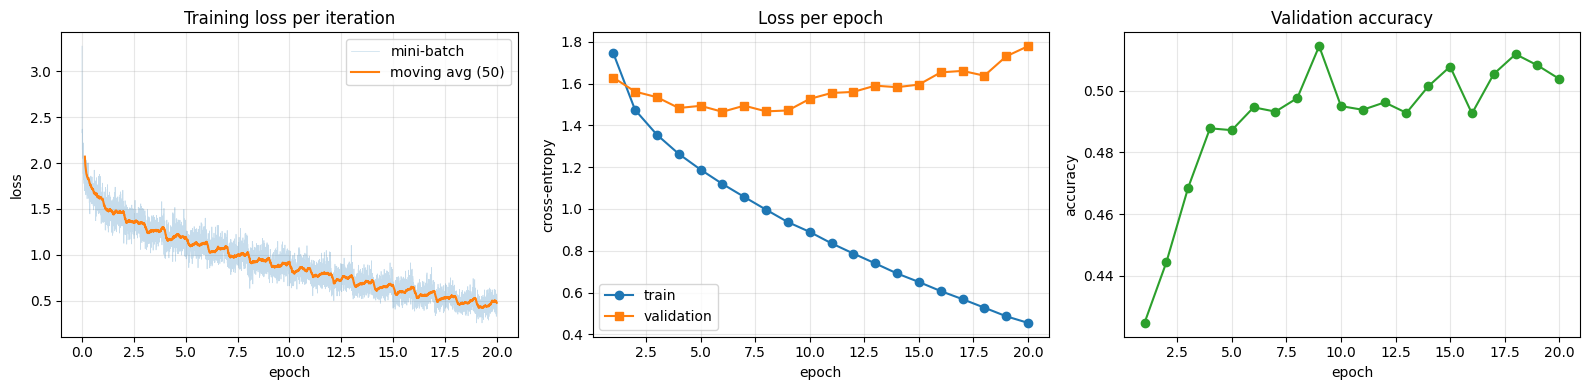

final val acc 0.5038 | best 0.5144 (epoch 9)


In [ ]:
T1_EPOCHS, T1_LR, T1_BS = E(20), 0.02, 128


def train_manual_mlp():
    set_seed(SEED)
    net = MLP([3072, 512, 256, 10], act='relu')
    Xf, Xvf = Xtr.flatten(1), Xva.flatten(1)
    H = {k: [] for k in ['train_loss', 'val_loss', 'val_acc', 'iter_loss']}
    t0 = time.time()
    for ep in range(T1_EPOCHS):
        losses = []
        for xb, yb in iterate(Xf, ytr, T1_BS):
            losses.append(net.loss(xb, yb))
            net.backward()
            net.sgd_step(T1_LR)
        losses = torch.stack(losses).cpu().numpy()
        H['iter_loss'] += losses.tolist(); H['train_loss'].append(float(losses.mean()))
        logits = net.forward(Xvf)
        H['val_loss'].append(net.criterion.forward(logits, yva).item())
        H['val_acc'].append((logits.argmax(1) == yva).float().mean().item())
        print(f'ep {ep + 1:2d}  train_loss {H["train_loss"][-1]:.4f}  val_loss {H["val_loss"][-1]:.4f}  '
              f'val_acc {H["val_acc"][-1]:.4f}  ({time.time() - t0:.0f}s)')
    return H


h1c = run_or_load('t1c_mlp', train_manual_mlp)
ep = np.arange(1, len(h1c['train_loss']) + 1)
it_per_ep = len(h1c['iter_loss']) / len(ep)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(np.arange(len(h1c['iter_loss'])) / it_per_ep, h1c['iter_loss'], alpha=0.25, lw=0.5, label='mini-batch')
ax[0].plot((np.arange(len(smooth(h1c['iter_loss']))) + 49) / it_per_ep, smooth(h1c['iter_loss']), label='moving avg (50)')
ax[0].set(xlabel='epoch', ylabel='loss', title='Training loss per iteration'); ax[0].legend()
ax[1].plot(ep, h1c['train_loss'], 'o-', label='train'); ax[1].plot(ep, h1c['val_loss'], 's-', label='validation')
ax[1].set(xlabel='epoch', ylabel='cross-entropy', title='Loss per epoch'); ax[1].legend()
ax[2].plot(ep, h1c['val_acc'], 'o-', c='C2'); ax[2].set(xlabel='epoch', ylabel='accuracy', title='Validation accuracy')
plt.tight_layout(); savefig('t1c_mlp_training'); plt.show()
print(f'final val acc {h1c["val_acc"][-1]:.4f} | best {max(h1c["val_acc"]):.4f} (epoch {int(np.argmax(h1c["val_acc"])) + 1})')

> **Interpretation.** _To be written from the results._
> <!-- points to cover: loss decreases; val loss starts rising while train loss keeps falling -> overfitting; MLP ~50-55% because flattening throws away spatial structure / no translation invariance -->

### (d) Per-layer gradient norm at initialisation: 10-layer MLP, sigmoid vs ReLU
3072 → 9 × 256 → 10 (10 linear layers). One forward/backward on 512 training images, $\|\partial L/\partial W_\ell\|_F$ per layer.
Sigmoid uses Xavier init, ReLU uses He init (the standard pairing); ReLU with Xavier init is added to separate the effect of the
activation from that of the initialisation.

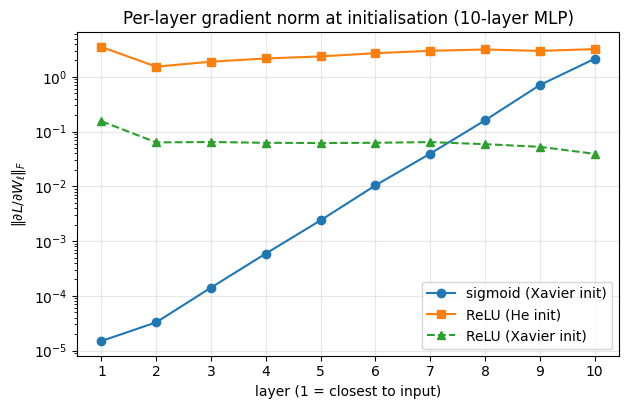

,layer 1,layer 2,layer 3,layer 4,layer 5,layer 6,layer 7,layer 8,layer 9,layer 10
sigmoid (Xavier init),1.49e-05,3.28e-05,1.41e-04,5.92e-04,2.40e-03,1.04e-02,3.96e-02,1.61e-01,7.09e-01,2.14e+00
ReLU (He init),3.51e+00,1.54e+00,1.90e+00,2.17e+00,2.37e+00,2.71e+00,3.00e+00,3.16e+00,2.98e+00,3.22e+00
ReLU (Xavier init),1.55e-01,6.35e-02,6.46e-02,6.24e-02,6.19e-02,6.25e-02,6.43e-02,5.89e-02,5.28e-02,3.93e-02


sigmoid (Xavier init)   ||g_1|| / ||g_10|| = 6.99e-06
ReLU (He init)          ||g_1|| / ||g_10|| = 1.09e+00
ReLU (Xavier init)      ||g_1|| / ||g_10|| = 3.94e+00


In [ ]:
def layer_grad_norms(act, init, depth=10, width=256, n=512, seed=SEED):
    set_seed(seed)
    net = MLP([3072] + [width] * (depth - 1) + [10], act=act, init=init)
    net.loss(Xtr[:n].flatten(1), ytr[:n]); net.backward()
    return [l.grads[0].norm().item() for l in net.linears]


cfgs = {'sigmoid (Xavier init)': ('sigmoid', 'xavier'), 'ReLU (He init)': ('relu', 'he'),
        'ReLU (Xavier init)': ('relu', 'xavier')}
gn = {k: layer_grad_norms(*v) for k, v in cfgs.items()}
json.dump(gn, open(os.path.join(RES_DIR, 't1d_gradnorms.json'), 'w'))
L = np.arange(1, 11)
plt.figure(figsize=(7, 4.2))
for (k, v), sty in zip(gn.items(), ['o-', 's-', '^--']):
    plt.semilogy(L, v, sty, label=k)
plt.xticks(L); plt.xlabel('layer (1 = closest to input)'); plt.ylabel(r'$\|\partial L / \partial W_\ell\|_F$')
plt.title('Per-layer gradient norm at initialisation (10-layer MLP)'); plt.legend()
savefig('t1d_gradnorm'); plt.show()
pd.set_option('display.float_format', '{:.2e}'.format)
display(pd.DataFrame(gn, index=[f'layer {i}' for i in L]).T)
for k, v in gn.items():
    print(f'{k:22s}  ||g_1|| / ||g_10|| = {v[0] / v[-1]:.2e}')

> **Interpretation.** _To be written from the results._
> <!-- points to cover: sigmoid: sigma' <= 0.25 so each layer multiplies the backward signal by ~0.25*||W|| -> geometric decay toward input (vanishing gradients, first layers barely learn); ReLU+He: derivative 1 on active half and He variance 2/n compensates -> roughly constant norms; ReLU+Xavier shows the init matters too -->

---
## Task 2 — Optimizers

### (a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses
* SGD (PyTorch convention): $d = g + \lambda\theta,\; b \leftarrow \mu b + d$ ($b_1 = d$), $\theta \leftarrow \theta - \eta b$
* Adam: $m \leftarrow \beta_1 m + (1-\beta_1) g,\; v \leftarrow \beta_2 v + (1-\beta_2) g^2,\;
  \hat m = m/(1-\beta_1^t),\; \hat v = v/(1-\beta_2^t),\; \theta \leftarrow \theta - \eta\, \hat m/(\sqrt{\hat v}+\epsilon)$

In [ ]:
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr=0.01, momentum=0.0, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, mu, wd = group['lr'], group['momentum'], group['weight_decay']
            for p in group['params']:
                if p.grad is None:
                    continue
                d = p.grad
                if wd != 0:
                    d = d.add(p, alpha=wd)
                if mu != 0:
                    state = self.state[p]
                    if 'buf' not in state:
                        state['buf'] = d.clone()
                    else:
                        state['buf'].mul_(mu).add_(d)
                    d = state['buf']
                p.add_(d, alpha=-lr)
        return loss


class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, (b1, b2), eps, wd = group['lr'], group['betas'], group['eps'], group['weight_decay']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if wd != 0:
                    g = g.add(p, alpha=wd)
                state = self.state[p]
                if not state:
                    state['t'] = 0
                    state['m'] = torch.zeros_like(p)
                    state['v'] = torch.zeros_like(p)
                state['t'] += 1
                t = state['t']
                state['m'].mul_(b1).add_(g, alpha=1 - b1)
                state['v'].mul_(b2).addcmul_(g, g, value=1 - b2)
                m_hat = state['m'] / (1 - b1 ** t)          # bias correction
                v_hat = state['v'] / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(eps), value=-lr)
        return loss

In [ ]:
def compare_with_torch(my_cls, torch_cls, kw, steps=100):
    """Train two identical float64 networks on the same CIFAR batches, one with each optimizer."""
    torch.manual_seed(0)
    net_a = nn.Sequential(nn.Flatten(), nn.Linear(3072, 64), nn.ReLU(), nn.Linear(64, 10)).double().to(device)
    net_b = nn.Sequential(nn.Flatten(), nn.Linear(3072, 64), nn.ReLU(), nn.Linear(64, 10)).double().to(device)
    net_b.load_state_dict(net_a.state_dict())
    oa, ob = my_cls(net_a.parameters(), **kw), torch_cls(net_b.parameters(), **kw)
    g = torch.Generator(device='cpu').manual_seed(1)
    max_loss_diff = 0.0
    for _ in range(steps):
        idx = torch.randint(0, len(Xtr), (64,), generator=g).to(device)
        xb, yb = Xtr[idx].double(), ytr[idx]
        losses = []
        for net, opt in ((net_a, oa), (net_b, ob)):
            opt.zero_grad(); loss = F.cross_entropy(net(xb), yb); loss.backward(); opt.step()
            losses.append(loss.item())
        max_loss_diff = max(max_loss_diff, abs(losses[0] - losses[1]))
    pa, pb = list(net_a.parameters()), list(net_b.parameters())
    return {'max |param diff|': max((a - b).abs().max().item() for a, b in zip(pa, pb)),
            'max |loss diff|': max_loss_diff,
            'allclose (all params)': all(torch.allclose(a, b) for a, b in zip(pa, pb))}


tests = [('SGD', MySGD, torch.optim.SGD, dict(lr=0.05)),
         ('SGD + momentum', MySGD, torch.optim.SGD, dict(lr=0.05, momentum=0.9)),
         ('SGD + momentum + wd', MySGD, torch.optim.SGD, dict(lr=0.05, momentum=0.9, weight_decay=5e-4)),
         ('Adam', MyAdam, torch.optim.Adam, dict(lr=1e-3)),
         ('Adam (betas .8/.99, wd)', MyAdam, torch.optim.Adam, dict(lr=3e-3, betas=(0.8, 0.99), weight_decay=1e-4))]
opt_check = pd.DataFrame([{'optimizer': n, 'hyper-parameters': str(kw), **compare_with_torch(a, b, kw)}
                          for n, a, b, kw in tests])
display(opt_check)
json.dump(opt_check.to_dict('records'), open(os.path.join(RES_DIR, 't2a_optcheck.json'), 'w'))

,optimizer,hyper-parameters,max |param diff|,max |loss diff|,allclose (all params)
0,SGD,{'lr': 0.05},0.00e+00,0.00e+00,True
1,SGD + momentum,"{'lr': 0.05, 'momentum': 0.9}",0.00e+00,0.00e+00,True
2,SGD + momentum + wd,"{'lr': 0.05, 'momentum': 0.9, 'weight_decay': ...",0.00e+00,0.00e+00,True
3,Adam,{'lr': 0.001},4.16e-17,4.44e-16,True
4,"Adam (betas .8/.99, wd)","{'lr': 0.003, 'betas': (0.8, 0.99), 'weight_de...",1.61e-16,4.44e-16,True


> **Interpretation.** _To be written from the results._
> <!-- points to cover: after 100 steps parameters agree to ~1e-15 (float64 round-off) -> implementations equal to torch.optim.SGD/Adam -->

### (b) Trajectories on $f(x,y) = \tfrac12(x^2 + 50y^2)$
Ill-conditioned quadratic: curvatures 1 and 50 (condition number 50). Plain GD is stable only for $\eta < 2/50 = 0.04$.
All runs start at $(-9, 2)$ for 60 steps, using the optimizers from (a).

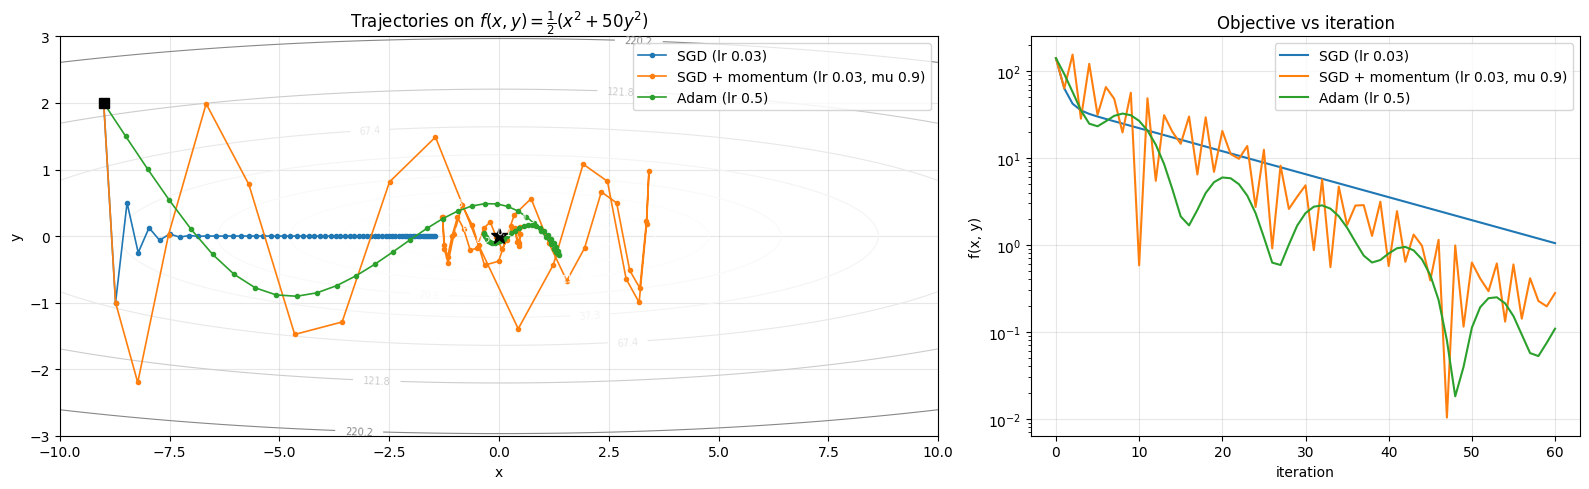

SGD (lr 0.03)                      final (x, y) = (-1.4473,  0.0000)   f = 1.05e+00
SGD + momentum (lr 0.03, mu 0.9)   final (x, y) = ( 0.3301,  0.0948)   f = 2.79e-01
Adam (lr 0.5)                      final (x, y) = (-0.3382,  0.0453)   f = 1.09e-01


In [ ]:
def f2(p):
    return 0.5 * (p[0] ** 2 + 50 * p[1] ** 2)


def trajectory(opt_cls, steps=60, start=(-9.0, 2.0), **kw):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = opt_cls([p], **kw)
    path, vals = [p.detach().clone()], [f2(p).item()]
    for _ in range(steps):
        opt.zero_grad(); f2(p).backward(); opt.step()
        path.append(p.detach().clone()); vals.append(f2(p).item())
    return torch.stack(path).numpy(), np.array(vals)


traj_cfg = {'SGD (lr 0.03)': (MySGD, dict(lr=0.03)),
            'SGD + momentum (lr 0.03, mu 0.9)': (MySGD, dict(lr=0.03, momentum=0.9)),
            'Adam (lr 0.5)': (MyAdam, dict(lr=0.5))}
trajs = {k: trajectory(c, **kw) for k, (c, kw) in traj_cfg.items()}

xx, yy = np.meshgrid(np.linspace(-10, 10, 400), np.linspace(-3, 3, 300))
fig, ax = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [1.6, 1]})
cs = ax[0].contour(xx, yy, 0.5 * (xx ** 2 + 50 * yy ** 2), levels=np.logspace(-1, 2.6, 15), cmap='Greys', linewidths=0.8)
ax[0].clabel(cs, fontsize=7, fmt='%.1f')
for (k, (path, vals)), c in zip(trajs.items(), ['C0', 'C1', 'C2']):
    ax[0].plot(path[:, 0], path[:, 1], 'o-', ms=3, lw=1.2, c=c, label=k)
    ax[1].semilogy(vals, c=c, label=k)
ax[0].plot(0, 0, 'k*', ms=12); ax[0].plot(-9, 2, 'ks', ms=7)
ax[0].set(xlabel='x', ylabel='y', title=r'Trajectories on $f(x,y)=\frac{1}{2}(x^2+50y^2)$'); ax[0].legend(loc='upper right')
ax[1].set(xlabel='iteration', ylabel='f(x, y)', title='Objective vs iteration'); ax[1].legend()
plt.tight_layout(); savefig('t2b_trajectories'); plt.show()
for k, (path, vals) in trajs.items():
    print(f'{k:34s} final (x, y) = ({path[-1, 0]: .4f}, {path[-1, 1]: .4f})   f = {vals[-1]:.2e}')

> **Interpretation.** _To be written from the results._
> <!-- points to cover: SGD: zig-zag across the steep y valley (step ~ 2/50 limit) and crawls along x (factor 1-0.03 per step); momentum accumulates velocity along the consistent x direction, damps y oscillation -> much faster but overshoots/spirals; Adam: per-coordinate normalisation -> first steps ~ lr*sign(g) (diagonal 45 deg path), ignores curvature differences, then oscillates around the minimum with fixed lr -->

### (c) Small CNN trained with each optimizer at three learning rates
CNN without batch norm (3 conv stages 32/64/128 → FC 256 → 10), 45k training images, batch 128, constant learning rate,
no augmentation. Learning rates are one decade apart around each optimizer's usual default.

In [ ]:
class SmallCNN(nn.Module):
    def __init__(self, bn=False, p_drop=0.0):
        super().__init__()

        def block(cin, cout):
            layers = [nn.Conv2d(cin, cout, 3, padding=1, bias=not bn)]
            if bn:
                layers.append(nn.BatchNorm2d(cout))
            return layers + [nn.ReLU(inplace=True)]

        self.features = nn.Sequential(*block(3, 32), *block(32, 32), nn.MaxPool2d(2),       # 16x16
                                      *block(32, 64), *block(64, 64), nn.MaxPool2d(2),      # 8x8
                                      *block(64, 128), nn.MaxPool2d(2))                     # 4x4
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(p_drop), nn.Linear(128 * 4 * 4, 256),
                                        nn.ReLU(inplace=True), nn.Dropout(p_drop), nn.Linear(256, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


print('SmallCNN parameters:', n_params(SmallCNN()))

T2_EPOCHS = E(10)
T2_GRID = {'SGD': (lambda ps, lr: MySGD(ps, lr=lr), [0.005, 0.05, 0.5]),
           'SGD + momentum': (lambda ps, lr: MySGD(ps, lr=lr, momentum=0.9), [0.001, 0.01, 0.1]),
           'Adam': (lambda ps, lr: MyAdam(ps, lr=lr), [1e-4, 1e-3, 1e-2])}

t2c = {}
for opt_name, (mk, lrs) in T2_GRID.items():
    for lr in lrs:
        key = f'{opt_name} lr={lr:g}'

        def run(mk=mk, lr=lr, key=key):
            set_seed(SEED)
            model = SmallCNN().to(device)
            return train(model, Xtr, ytr, Xva, yva, epochs=T2_EPOCHS, make_opt=lambda ps: mk(ps, lr), name=key)

        t2c[(opt_name, lr)] = run_or_load('t2c_' + key, run)

SmallCNN parameters: 666538
[SGD lr=0.005] ep   2/10  train_loss 2.3015  val_acc 0.1328  (11s)
[SGD lr=0.005] ep   4/10  train_loss 2.2958  val_acc 0.1418  (18s)
[SGD lr=0.005] ep   6/10  train_loss 2.1973  val_acc 0.2096  (25s)
[SGD lr=0.005] ep   8/10  train_loss 2.0255  val_acc 0.2902  (32s)
[SGD lr=0.005] ep  10/10  train_loss 1.8535  val_acc 0.3118  (39s)
[SGD lr=0.05] ep   2/10  train_loss 1.8446  val_acc 0.2896  (7s)
[SGD lr=0.05] ep   4/10  train_loss 1.3810  val_acc 0.5006  (14s)
[SGD lr=0.05] ep   6/10  train_loss 1.1186  val_acc 0.6010  (22s)
[SGD lr=0.05] ep   8/10  train_loss 0.8988  val_acc 0.6462  (29s)
[SGD lr=0.05] ep  10/10  train_loss 0.7050  val_acc 0.6806  (36s)
[SGD lr=0.5] ep   2/10  train_loss 2.2616  val_acc 0.0934  (7s)
[SGD lr=0.5] ep   4/10  train_loss 2.3038  val_acc 0.1004  (14s)
[SGD lr=0.5] diverged at epoch 6
[SGD lr=0.5] ep   6/10  train_loss nan  val_acc 0.1000  (21s)
[SGD + momentum lr=0.001] ep   2/10  train_loss 2.2986  val_acc 0.1416  (7s)
[SGD + 

lr,0.0001,0.0010,0.0050,0.0100,0.0500,0.1000,0.5000
optimizer,,,,,,,
Adam,0.6406,0.7572,NaN,0.0964,NaN,NaN,NaN
SGD,NaN,NaN,0.3118,NaN,0.6806,NaN,0.1000
SGD + momentum,NaN,0.4706,NaN,0.7370,NaN,0.5308,NaN


best learning rate (final val acc): {'SGD': 0.05, 'SGD + momentum': 0.01, 'Adam': 0.001}


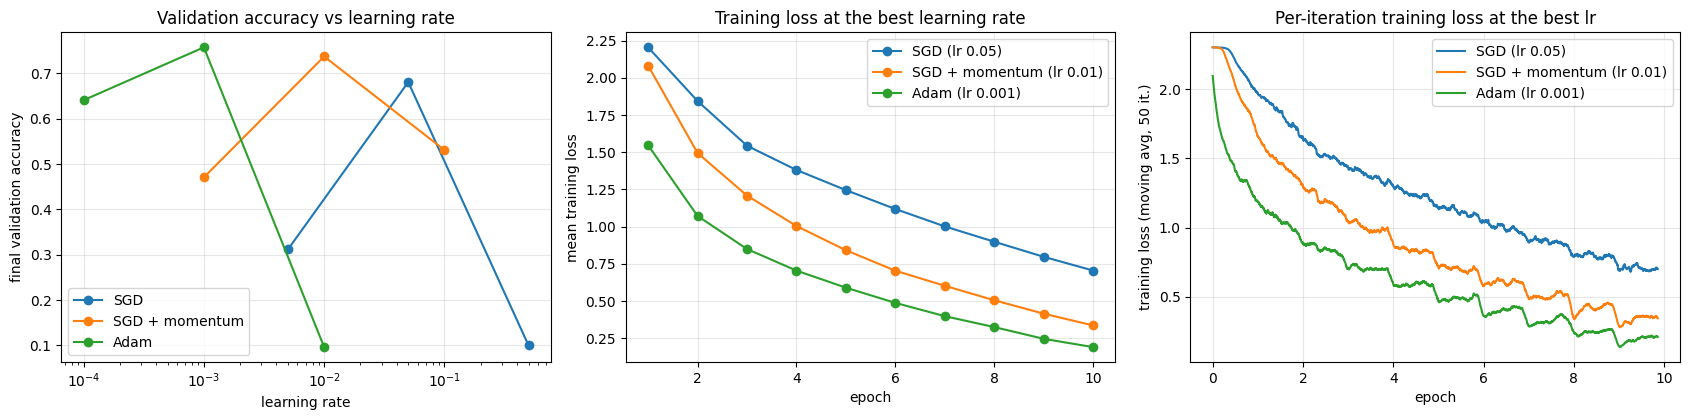

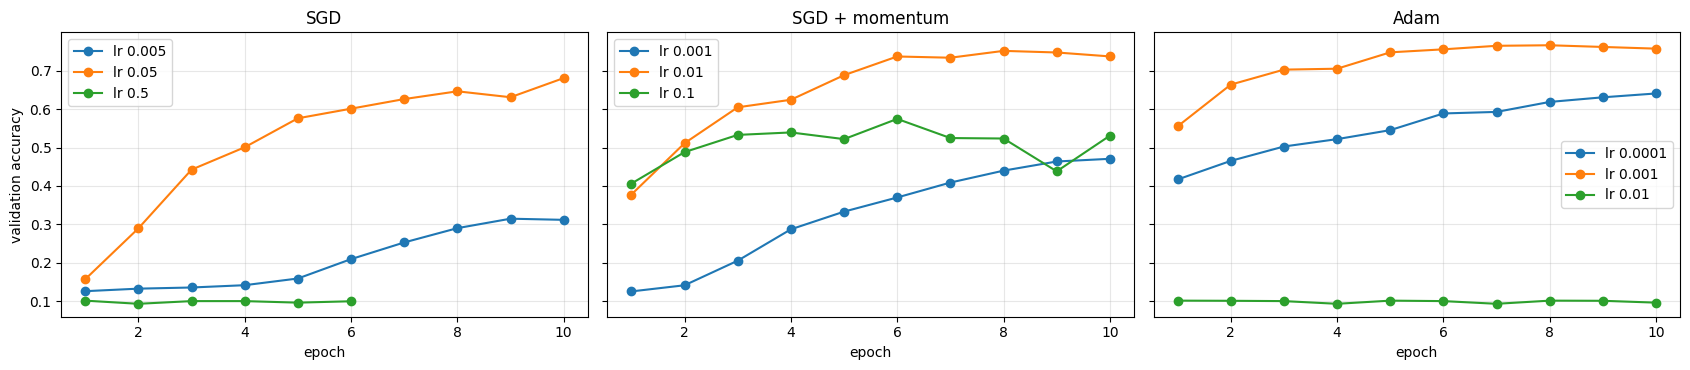

In [ ]:
rows = [{'optimizer': o, 'lr': lr, 'final val acc': h['val_acc'][-1], 'best val acc': max(h['val_acc']),
         'final train loss': h['train_loss'][-1], 'diverged': h.get('diverged', False)} for (o, lr), h in t2c.items()]
t2c_df = pd.DataFrame(rows)
pd.set_option('display.float_format', '{:.4f}'.format)
display(t2c_df.pivot(index='optimizer', columns='lr', values='final val acc'))
best_lr = {o: max(lrs, key=lambda lr: t2c[(o, lr)]['val_acc'][-1]) for o, (_, lrs) in T2_GRID.items()}
print('best learning rate (final val acc):', best_lr)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
for i, (o, (_, lrs)) in enumerate(T2_GRID.items()):
    ax[0].semilogx(lrs, [t2c[(o, lr)]['val_acc'][-1] for lr in lrs], 'o-', c=f'C{i}', label=o)
    h = t2c[(o, best_lr[o])]
    ax[1].plot(np.arange(1, len(h['train_loss']) + 1), h['train_loss'], 'o-', c=f'C{i}', label=f'{o} (lr {best_lr[o]:g})')
    s = smooth(h['iter_loss'], 50)
    ax[2].plot(np.arange(len(s)) / (len(h['iter_loss']) / len(h['train_loss'])), s, c=f'C{i}', label=f'{o} (lr {best_lr[o]:g})')
ax[0].set(xlabel='learning rate', ylabel='final validation accuracy', title='Validation accuracy vs learning rate'); ax[0].legend()
ax[1].set(xlabel='epoch', ylabel='mean training loss', title='Training loss at the best learning rate'); ax[1].legend()
ax[2].set(xlabel='epoch', ylabel='training loss (moving avg, 50 it.)', title='Per-iteration training loss at the best lr'); ax[2].legend()
plt.tight_layout(); savefig('t2c_optimizers'); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 3.8), sharey=True)
for ax_, (o, (_, lrs)) in zip(axes, T2_GRID.items()):
    for lr in lrs:
        ax_.plot(np.arange(1, len(t2c[(o, lr)]['val_acc']) + 1), t2c[(o, lr)]['val_acc'], 'o-', label=f'lr {lr:g}')
    ax_.set(title=o, xlabel='epoch'); ax_.legend()
axes[0].set_ylabel('validation accuracy')
plt.tight_layout(); savefig('t2c_val_curves'); plt.show()

> **Interpretation.** _To be written from the results._
> <!-- points to cover: sensitivity: width of the good lr range per optimizer; plain SGD needs large lr (slow at small lr); momentum effective lr = lr/(1-mu); Adam converges fast at 1e-3 but 1e-2 unstable / worse generalisation; overfitting visible as val acc peaking -->

---
## Task 3 — Regularization and residual connections

### (a) Regularization on 5k training images
Small CNN **with batch norm**, trained on the first 5,000 images of the training split and validated on the 5k validation split.
Every configuration: SGD momentum 0.9, lr 0.05 with cosine decay, batch 128, 60 epochs. Each regulariser is added to the baseline alone,
then all together. Train accuracy is measured on the 5k clean training images in eval mode, so it is comparable across methods
(mixup/cutout batches are not "clean").

In [ ]:
T3A_EPOCHS = E(60)
X5k, y5k = Xtr[:5000], ytr[:5000]
print('5k subset class counts:', torch.bincount(y5k.cpu(), minlength=10).tolist())

T3A = {'baseline': {},
       'weight decay': dict(wd=5e-4),
       'dropout': dict(p_drop=0.5),
       'flip+crop': dict(flipcrop=True),
       'cutout': dict(cut=True),
       'mixup': dict(mixup=1.0),
       'all combined': dict(wd=5e-4, p_drop=0.5, flipcrop=True, cut=True, mixup=1.0)}

t3a = {}
for name, c in T3A.items():
    def run(c=c, name=name):
        set_seed(SEED)
        model = SmallCNN(bn=True, p_drop=c.get('p_drop', 0.0)).to(device)
        return train(model, X5k, y5k, Xva, yva, epochs=T3A_EPOCHS, sched='cosine',
                     make_opt=lambda ps: torch.optim.SGD(ps, lr=0.05, momentum=0.9, weight_decay=c.get('wd', 0.0)),
                     aug=make_aug(c.get('flipcrop', False), c.get('cut', False)), mixup_alpha=c.get('mixup', 0.0),
                     amp=USE_AMP, track_train_acc=True, name=name)
    t3a[name] = run_or_load('t3a_' + name, run)

5k subset class counts: [511, 510, 506, 509, 502, 472, 500, 470, 500, 520]
[baseline] ep  12/60  train_loss 0.6025  val_acc 0.5656  train_acc 0.7452  (8s)
[baseline] ep  24/60  train_loss 0.0140  val_acc 0.6818  train_acc 0.9990  (13s)
[baseline] ep  36/60  train_loss 0.0119  val_acc 0.6620  train_acc 0.9986  (18s)
[baseline] ep  48/60  train_loss 0.0043  val_acc 0.6758  train_acc 0.9998  (23s)
[baseline] ep  60/60  train_loss 0.0037  val_acc 0.6784  train_acc 0.9998  (28s)
[weight decay] ep  12/60  train_loss 0.6473  val_acc 0.5940  train_acc 0.7766  (5s)
[weight decay] ep  24/60  train_loss 0.0068  val_acc 0.6800  train_acc 1.0000  (10s)
[weight decay] ep  36/60  train_loss 0.0147  val_acc 0.6792  train_acc 1.0000  (15s)
[weight decay] ep  48/60  train_loss 0.0039  val_acc 0.6834  train_acc 1.0000  (20s)
[weight decay] ep  60/60  train_loss 0.0030  val_acc 0.6874  train_acc 1.0000  (24s)
[dropout] ep  12/60  train_loss 1.5690  val_acc 0.4754  train_acc 0.5092  (5s)
[dropout] ep  24/6

,train acc,val acc,gap (train - val),best val acc,final val loss
config,,,,,
baseline,0.9998,0.6784,0.3214,0.6826,1.7933
weight decay,1.0000,0.6874,0.3126,0.6896,1.4893
dropout,0.9680,0.7112,0.2568,0.7132,1.0045
flip+crop,0.9420,0.7532,0.1888,0.7554,0.8331
cutout,0.9996,0.6966,0.3030,0.6980,1.4384
mixup,0.9994,0.6644,0.3350,0.6716,1.0338
all combined,0.6160,0.5880,0.0280,0.5936,1.1920


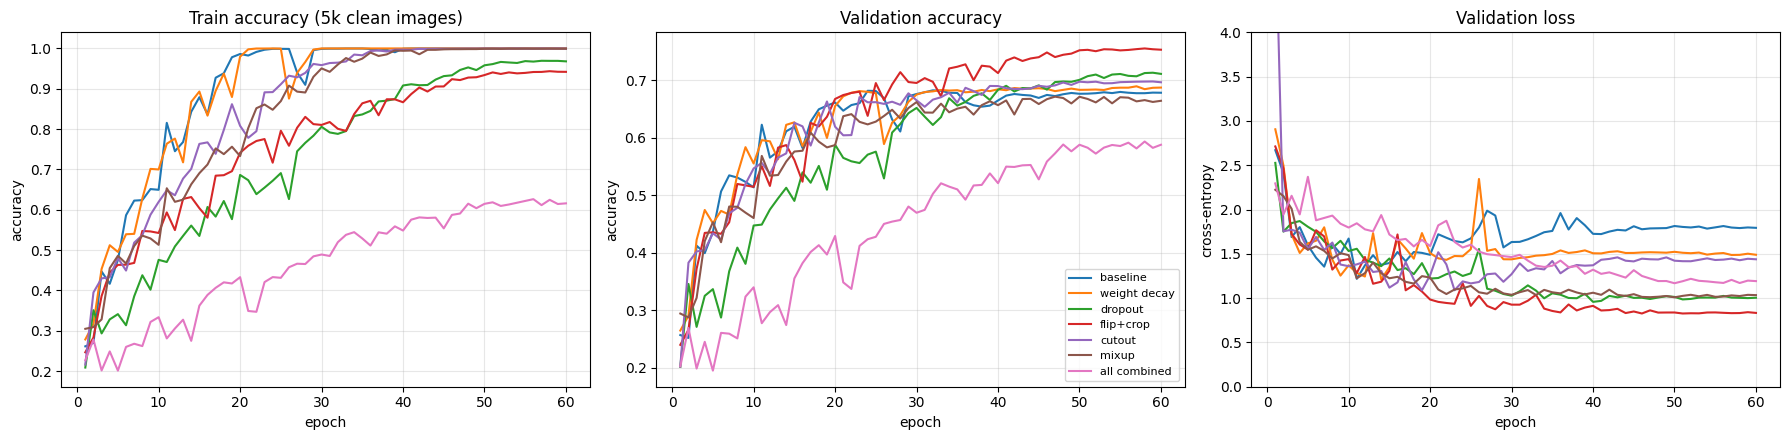

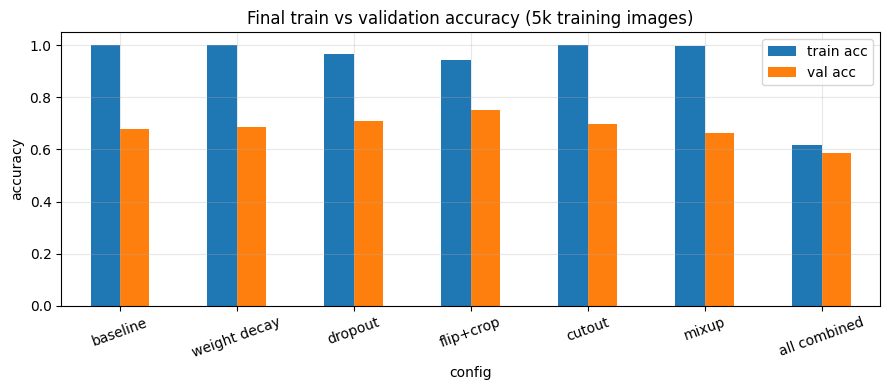

In [ ]:
t3a_df = pd.DataFrame([{'config': n, 'train acc': h['train_acc'][-1], 'val acc': h['val_acc'][-1],
                        'gap (train - val)': h['train_acc'][-1] - h['val_acc'][-1],
                        'best val acc': max(h['val_acc']), 'final val loss': h['val_loss'][-1]}
                       for n, h in t3a.items()]).set_index('config')
display(t3a_df)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for i, (n, h) in enumerate(t3a.items()):
    e = np.arange(1, len(h['val_acc']) + 1)
    ax[0].plot(e, h['train_acc'], c=f'C{i}', label=n)
    ax[1].plot(e, h['val_acc'], c=f'C{i}', label=n)
    ax[2].plot(e, h['val_loss'], c=f'C{i}', label=n)
ax[0].set(xlabel='epoch', ylabel='accuracy', title='Train accuracy (5k clean images)')
ax[1].set(xlabel='epoch', ylabel='accuracy', title='Validation accuracy')
ax[2].set(xlabel='epoch', ylabel='cross-entropy', title='Validation loss', ylim=(0, 4))
ax[1].legend(fontsize=8)
plt.tight_layout(); savefig('t3a_curves'); plt.show()

ax = t3a_df[['train acc', 'val acc']].plot.bar(figsize=(9, 4), rot=20)
ax.set_ylabel('accuracy'); ax.set_title('Final train vs validation accuracy (5k training images)'); ax.set_ylim(0, 1.05)
plt.tight_layout(); savefig('t3a_bars'); plt.show()

> **Interpretation.** _To be written from the results._
> <!-- points to cover: baseline memorises 5k images (train ~100%, large gap); which regulariser shrinks the gap most; augmentation (flip+crop) > explicit regularisers when data are scarce; mixup/cutout lower train acc; combined: smallest gap / best val (or over-regularised in 60 epochs?) -->

### (b) Plain vs residual networks of depth $6n+2$ (8, 20, 56)
CIFAR ResNet (He et al., 2016): 3×3 conv (16) → three stages of $n$ basic blocks with 16/32/64 channels (stride 2 at the start of stages 2
and 3) → global average pooling → FC. Batch norm after every conv, Kaiming (fan-out) initialisation.
The residual network uses the parameter-free identity shortcut (option A: subsample + zero-pad channels), so both families have
**exactly the same layers and parameters** — the shortcut addition is the only difference.
Training: SGD momentum 0.9, lr 0.1, weight decay 1e-4, cosine decay, flip+crop, batch 128, 30 epochs on 45k images.

In [ ]:
class ShortcutA(nn.Module):
    """Parameter-free identity shortcut: spatial subsampling + zero-padding of the extra channels."""
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.stride, self.extra = stride, cout - cin

    def forward(self, x):
        if self.stride > 1:
            x = x[:, :, ::self.stride, ::self.stride]
        if self.extra > 0:
            x = F.pad(x, (0, 0, 0, 0, self.extra // 2, self.extra - self.extra // 2))
        return x


class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride=1, shortcut='A'):          # shortcut in {'A', 'B', None}
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False); self.bn2 = nn.BatchNorm2d(cout)
        if shortcut is None:
            self.shortcut = None                                     # plain network
        elif shortcut == 'A' or (stride == 1 and cin == cout):
            self.shortcut = ShortcutA(cin, cout, stride)             # identity
        else:                                                        # 'B': 1x1 projection when the shape changes
            self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.shortcut is not None:
            out = out + self.shortcut(x)
        return F.relu(out)


class CifarResNet(nn.Module):
    def __init__(self, blocks=(3, 3, 3), widths=(16, 32, 64), shortcut='A', num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True))
        layers, cin = [], widths[0]
        for s, (n, w) in enumerate(zip(blocks, widths)):
            for b in range(n):
                layers.append(BasicBlock(cin, w, 2 if (s > 0 and b == 0) else 1, shortcut))
                cin = w
        self.blocks = nn.Sequential(*layers)
        self.fc = nn.Linear(cin, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.blocks(self.stem(x))
        return self.fc(F.adaptive_avg_pool2d(x, 1).flatten(1))


def cifar_net(depth, residual):
    assert (depth - 2) % 6 == 0
    n = (depth - 2) // 6
    return CifarResNet((n, n, n), (16, 32, 64), shortcut='A' if residual else None)


for d in (8, 20, 56):
    print(f'depth {d:2d}: plain {n_params(cifar_net(d, False)):,} params | residual {n_params(cifar_net(d, True)):,} params')

depth  8: plain 75,290 params | residual 75,290 params
depth 20: plain 269,722 params | residual 269,722 params
depth 56: plain 853,018 params | residual 853,018 params


In [ ]:
T3B_EPOCHS = E(30)
DEPTHS = (8, 20, 56)
t3b = {}
for depth in DEPTHS:
    for residual in (False, True):
        key = f'{"residual" if residual else "plain"}-{depth}'

        def run(depth=depth, residual=residual, key=key):
            set_seed(SEED)
            model = cifar_net(depth, residual).to(device)
            return train(model, Xtr, ytr, Xva, yva, epochs=T3B_EPOCHS, sched='cosine', aug=make_aug(flipcrop=True),
                         make_opt=lambda ps: torch.optim.SGD(ps, lr=0.1, momentum=0.9, weight_decay=1e-4),
                         amp=USE_AMP, track_train_acc=True, name=key)
        t3b[key] = run_or_load('t3b_' + key, run)

[plain-8] ep   6/30  train_loss 0.7794  val_acc 0.7186  train_acc 0.7248  (17s)
[plain-8] ep  12/30  train_loss 0.5903  val_acc 0.7626  train_acc 0.7848  (31s)
[plain-8] ep  18/30  train_loss 0.4886  val_acc 0.8154  train_acc 0.8372  (45s)
[plain-8] ep  24/30  train_loss 0.4182  val_acc 0.8392  train_acc 0.8696  (59s)
[plain-8] ep  30/30  train_loss 0.3840  val_acc 0.8420  train_acc 0.8736  (73s)
[residual-8] ep   6/30  train_loss 0.7859  val_acc 0.7014  train_acc 0.7038  (15s)
[residual-8] ep  12/30  train_loss 0.6073  val_acc 0.7664  train_acc 0.7900  (30s)
[residual-8] ep  18/30  train_loss 0.5079  val_acc 0.8042  train_acc 0.8360  (45s)
[residual-8] ep  24/30  train_loss 0.4386  val_acc 0.8314  train_acc 0.8618  (60s)
[residual-8] ep  30/30  train_loss 0.4034  val_acc 0.8390  train_acc 0.8714  (76s)
[plain-20] ep   6/30  train_loss 0.7626  val_acc 0.7350  train_acc 0.7476  (32s)
[plain-20] ep  12/30  train_loss 0.5234  val_acc 0.7922  train_acc 0.8198  (64s)
[plain-20] ep  18/30  t

/tmp/ipykernel_3232/2880168224.py:51: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


[plain-56] ep   6/30  train_loss 1.7445  val_acc 0.3550  train_acc 0.3510  (86s)
[plain-56] ep  12/30  train_loss 1.5898  val_acc 0.4392  train_acc 0.4428  (172s)
[plain-56] ep  18/30  train_loss 1.4305  val_acc 0.4934  train_acc 0.4986  (258s)
[plain-56] ep  24/30  train_loss 1.2869  val_acc 0.5518  train_acc 0.5600  (345s)
[plain-56] ep  30/30  train_loss 1.2053  val_acc 0.5710  train_acc 0.5858  (431s)
[residual-56] ep   6/30  train_loss 0.7939  val_acc 0.7248  train_acc 0.7432  (90s)
[residual-56] ep  12/30  train_loss 0.4737  val_acc 0.7870  train_acc 0.8144  (181s)
[residual-56] ep  18/30  train_loss 0.3117  val_acc 0.8600  train_acc 0.8988  (272s)
[residual-56] ep  24/30  train_loss 0.1895  val_acc 0.8822  train_acc 0.9526  (363s)
[residual-56] ep  30/30  train_loss 0.1362  val_acc 0.8876  train_acc 0.9648  (453s)


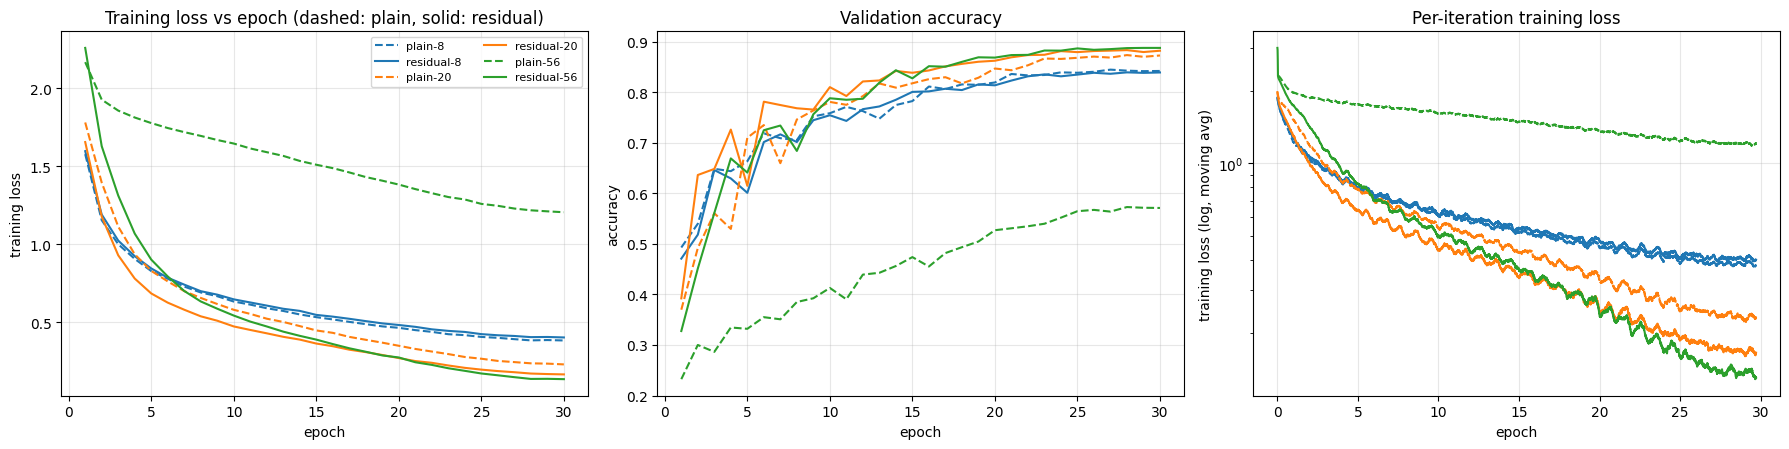

,depth,params,final train loss,train acc,val acc,time (s)
network,,,,,,
plain-8,8,75290,0.3840,0.8736,0.8420,73.0397
residual-8,8,75290,0.4034,0.8714,0.8390,75.6520
plain-20,20,269722,0.2308,0.9288,0.8726,160.8202
residual-20,20,269722,0.1667,0.9510,0.8820,170.4115
plain-56,56,853018,1.2053,0.5858,0.5710,430.8767
residual-56,56,853018,0.1362,0.9648,0.8876,453.4147


In [25]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
for i, d in enumerate(DEPTHS):
    for residual, ls in ((False, '--'), (True, '-')):
        key = f'{"residual" if residual else "plain"}-{d}'
        h = t3b[key]; e = np.arange(1, len(h['train_loss']) + 1)
        ax[0].plot(e, h['train_loss'], ls, c=f'C{i}', label=key)
        ax[1].plot(e, h['val_acc'], ls, c=f'C{i}', label=key)
        s = smooth(h['iter_loss'], 100)
        ax[2].semilogy(np.arange(len(s)) / (len(h['iter_loss']) / len(e)), s, ls, c=f'C{i}', label=key)
ax[0].set(xlabel='epoch', ylabel='training loss', title='Training loss vs epoch (dashed: plain, solid: residual)')
ax[1].set(xlabel='epoch', ylabel='accuracy', title='Validation accuracy')
ax[2].set(xlabel='epoch', ylabel='training loss (log, moving avg)', title='Per-iteration training loss')
ax[0].legend(ncol=2, fontsize=8)
plt.tight_layout(); savefig('t3b_plain_vs_residual'); plt.show()

t3b_df = pd.DataFrame([{'network': k, 'depth': int(k.split('-')[1]), 'params': h['params'],
                        'final train loss': h['train_loss'][-1], 'train acc': h['train_acc'][-1],
                        'val acc': h['val_acc'][-1], 'time (s)': h['time']} for k, h in t3b.items()])
display(t3b_df.sort_values(['depth', 'network']).set_index('network'))

Supporting diagnostic: gradient norm of each block's first conv at initialisation (one batch of 256 images) for the 56-layer networks.

In [ ]:
def block_grad_norms(depth, residual, n=256):
    set_seed(SEED)
    net = cifar_net(depth, residual).to(device).train()
    F.cross_entropy(net(Xtr[:n]), ytr[:n]).backward()
    return [b.conv1.weight.grad.norm().item() for b in net.blocks]


gn56 = {'plain-56': block_grad_norms(56, False), 'residual-56': block_grad_norms(56, True)}
json.dump(gn56, open(os.path.join(RES_DIR, 't3b_gradnorm56.json'), 'w'))
plt.figure(figsize=(8, 3.8))
for k, v in gn56.items():
    plt.semilogy(np.arange(1, len(v) + 1), v, 'o-', ms=3, label=k)
plt.xlabel('residual block (1 = closest to input)'); plt.ylabel('||dL/dW|| of conv1')
plt.title('Gradient norm per block at initialisation (depth 56)'); plt.legend()
savefig('t3b_gradnorm56'); plt.show()

> **Interpretation.** _To be written from the results._
> <!-- points to cover: degradation problem: plain-56 has HIGHER training loss than plain-20 (not overfitting - it's optimisation); residual nets: deeper -> lower training loss; identity shortcut gives an additive path for forward signal and backward gradient (dL/dx_l = dL/dx_L * (1 + ...)), blocks only need to learn a residual near zero; at depth 8 the two are similar -->

---
## Task 4 — Best CNN with ≤ 500k parameters and ≤ 20 epochs (optional)

**Design.** A wider, shallower ResNet: stem 3×3 conv (32) → stages of [2, 2, 1] basic blocks with 32/64/128 channels
(stride 2 between stages) → global average pooling → FC. Projection (1×1 conv) shortcuts where the shape changes. Most of the
compute stays at high resolution; most of the parameters are in the last (8×8) stage.

**Training recipe (proposed).** SGD with Nesterov momentum 0.9, one-cycle learning-rate schedule (peak 0.1), weight decay 5e-4,
label smoothing 0.1, flip + crop + cutout (16×16), batch 128, mixed precision, 20 epochs.

**Ablation.** Each run removes / swaps one design choice of the proposed recipe. Model selection is done on the validation split; the
selected model is evaluated **once** on the test set at the end.

In [21]:
T4_EPOCHS = E(20)


def t4_model(residual=True):
    return CifarResNet(blocks=(2, 2, 1), widths=(32, 64, 128), shortcut='B' if residual else None)


print(f'Task 4 model: {n_params(t4_model()):,} parameters (plain variant {n_params(t4_model(False)):,})')
assert n_params(t4_model()) <= 500_000

T4_BASE = dict(residual=True, flipcrop=True, cut=True, wd=5e-4, opt='sgd', ls=0.1)
T4_ABLATION = {'proposed': {},
               'no shortcut (plain)': dict(residual=False),
               'no cutout (flip+crop only)': dict(cut=False),
               'no augmentation': dict(flipcrop=False, cut=False),
               'no weight decay': dict(wd=0.0),
               'AdamW instead of SGD': dict(opt='adamw'),
               'no label smoothing': dict(ls=0.0)}


def t4_run(name, overrides):
    c = {**T4_BASE, **overrides}
    set_seed(SEED)
    model = t4_model(c['residual']).to(device)
    if c['opt'] == 'sgd':
        mk = lambda ps: torch.optim.SGD(ps, lr=0.1, momentum=0.9, nesterov=True, weight_decay=c['wd'])
    else:  # decoupled weight decay; 0.05 is the usual AdamW setting, scaled to 0 when 'no weight decay'
        mk = lambda ps: torch.optim.AdamW(ps, lr=3e-3, weight_decay=0.05 if c['wd'] else 0.0)
    h = train(model, Xtr, ytr, Xva, yva, epochs=T4_EPOCHS, make_opt=mk, sched='onecycle',
              aug=make_aug(c['flipcrop'], c['cut']), label_smoothing=c['ls'], amp=USE_AMP,
              track_train_acc=True, name=name)
    torch.save(model.state_dict(), os.path.join(RES_DIR, 't4_' + name.replace(' ', '_').replace('/', '-') + '.pt'))
    h['config'] = c
    return h


t4 = {name: run_or_load('t4_' + name, lambda name=name, o=o: t4_run(name, o)) for name, o in T4_ABLATION.items()}

Task 4 model: 401,194 parameters (plain variant 390,570)
[proposed] ep   4/20  train_loss 1.3594  val_acc 0.5092  train_acc 0.5258  (27s)
[proposed] ep   8/20  train_loss 1.1414  val_acc 0.6922  train_acc 0.7194  (52s)
[proposed] ep  12/20  train_loss 1.0527  val_acc 0.7796  train_acc 0.7942  (77s)
[proposed] ep  16/20  train_loss 0.9634  val_acc 0.8298  train_acc 0.8590  (102s)
[proposed] ep  20/20  train_loss 0.8574  val_acc 0.8864  train_acc 0.9222  (127s)
[no shortcut (plain)] ep   4/20  train_loss 1.3300  val_acc 0.5146  train_acc 0.5244  (22s)
[no shortcut (plain)] ep   8/20  train_loss 1.1285  val_acc 0.6740  train_acc 0.6866  (44s)
[no shortcut (plain)] ep  12/20  train_loss 1.0466  val_acc 0.7678  train_acc 0.7886  (67s)
[no shortcut (plain)] ep  16/20  train_loss 0.9597  val_acc 0.8114  train_acc 0.8502  (89s)
[no shortcut (plain)] ep  20/20  train_loss 0.8525  val_acc 0.8876  train_acc 0.9194  (111s)
[no cutout (flip+crop only)] ep   4/20  train_loss 1.2048  val_acc 0.6452  

,params,train acc,val acc,Δ val acc vs proposed,time (s)
run,,,,,
proposed,401194,0.9222,0.8864,0.0000,126.8959
no shortcut (plain),390570,0.9194,0.8876,0.0012,111.0348
no cutout (flip+crop only),401194,0.9450,0.8962,0.0098,123.0720
no augmentation,401194,1.0000,0.8568,-0.0296,120.8408
no weight decay,401194,0.9058,0.8656,-0.0208,123.7813
AdamW instead of SGD,401194,0.9144,0.8830,-0.0034,126.7436
no label smoothing,401194,0.9212,0.8836,-0.0028,123.8965


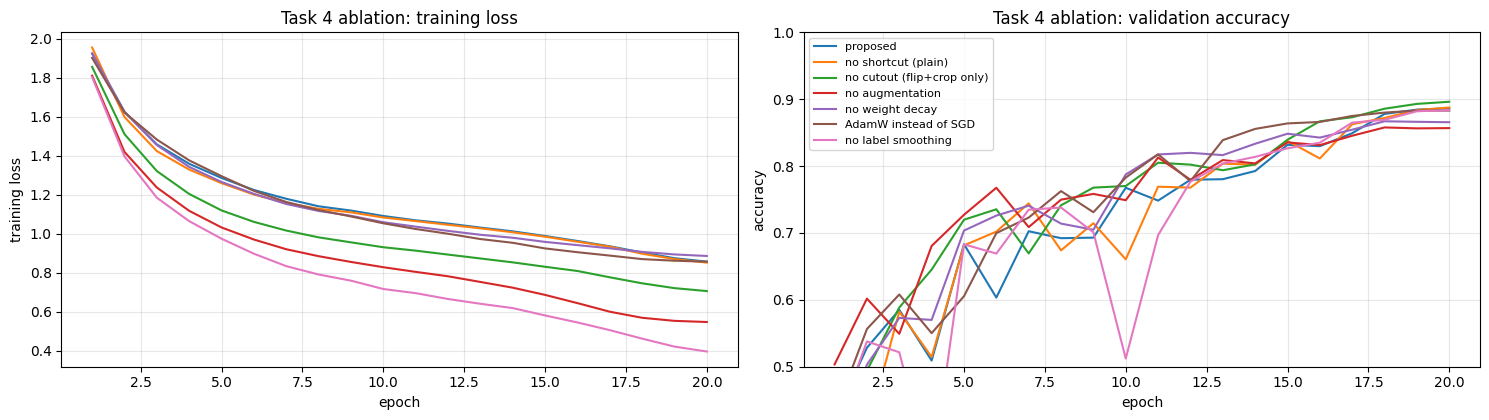

In [22]:
t4_df = pd.DataFrame([{'run': n, 'params': h['params'], 'train acc': h['train_acc'][-1], 'val acc': h['val_acc'][-1],
                       'Δ val acc vs proposed': h['val_acc'][-1] - t4['proposed']['val_acc'][-1],
                       'time (s)': h['time']} for n, h in t4.items()]).set_index('run')
display(t4_df)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
for i, (n, h) in enumerate(t4.items()):
    e = np.arange(1, len(h['val_acc']) + 1)
    ax[0].plot(e, h['train_loss'], c=f'C{i}', label=n)
    ax[1].plot(e, h['val_acc'], c=f'C{i}', label=n)
ax[0].set(xlabel='epoch', ylabel='training loss', title='Task 4 ablation: training loss')
ax[1].set(xlabel='epoch', ylabel='accuracy', title='Task 4 ablation: validation accuracy', ylim=(0.5, 1))
ax[1].legend(fontsize=8)
plt.tight_layout(); savefig('t4_ablation'); plt.show()

### Final model — test set (evaluated once)
The configuration with the highest validation accuracy is selected and its saved weights are evaluated on the CIFAR-10 test set.
This is the only place in the notebook where the test set is touched.

In [23]:
def final_test():
    best = max(t4, key=lambda n: t4[n]['val_acc'][-1])
    model = t4_model(t4[best]['config']['residual']).to(device)
    model.load_state_dict(torch.load(os.path.join(RES_DIR, 't4_' + best.replace(' ', '_').replace('/', '-') + '.pt'),
                                     map_location=device, weights_only=True))
    _test = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True)
    Xte = normalize(torch.tensor(_test.data).permute(0, 3, 1, 2).float().div_(255)).to(device)
    yte = torch.tensor(_test.targets).to(device)
    test_loss, test_acc = evaluate(model, Xte, yte)
    with torch.no_grad():
        model.eval()
        pred = torch.cat([model(Xte[i:i + 1000]).argmax(1) for i in range(0, len(Xte), 1000)])
    per_class = [(pred[yte == c] == c).float().mean().item() for c in range(10)]
    return {'selected run': best, 'params': n_params(model), 'val acc': t4[best]['val_acc'][-1],
            'test acc': test_acc, 'test loss': test_loss, 'per-class test acc': dict(zip(CLASSES, per_class))}


t4_test = run_or_load('t4_final_test', final_test)       # cached: the test set is evaluated only once
print(json.dumps(t4_test, indent=2))

{
  "selected run": "no cutout (flip+crop only)",
  "params": 401194,
  "val acc": 0.8962,
  "test acc": 0.8949,
  "test loss": 0.35871846313476563,
  "per-class test acc": {
    "airplane": 0.9220000505447388,
    "automobile": 0.9440000653266907,
    "bird": 0.8360000252723694,
    "cat": 0.7910000085830688,
    "deer": 0.8880000710487366,
    "dog": 0.8390000462532043,
    "frog": 0.9350000619888306,
    "horse": 0.9240000247955322,
    "ship": 0.9420000314712524,
    "truck": 0.9280000329017639
  }
}


> **Interpretation.** _To be written from the results._
> <!-- points to cover: ablation ranking: which choice matters most (likely augmentation, then shortcut), wd and label smoothing smaller; val vs test acc close -> no overfitting to val; weakest classes (cat/dog) -->

---
## Export results
Bundles all figures and result JSON files into `a2_outputs.zip` (downloaded automatically on Colab).

In [24]:
summary = {
    't1c_mlp_final_val_acc': h1c['val_acc'][-1],
    't2c_final_val_acc': {f'{o} lr={lr:g}': h['val_acc'][-1] for (o, lr), h in t2c.items()},
    't3a': t3a_df.reset_index().to_dict('records'),
    't3b': t3b_df.to_dict('records'),
    't4_ablation': t4_df.reset_index().to_dict('records'),
    't4_test': t4_test,
}
with open(os.path.join(RES_DIR, 'summary.json'), 'w') as f:
    json.dump(summary, f, indent=2)

with zipfile.ZipFile('a2_outputs.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for d in (FIG_DIR, RES_DIR):
        for fn in sorted(os.listdir(d)):
            if not fn.endswith('.pt'):
                z.write(os.path.join(d, fn))
print('wrote a2_outputs.zip')
try:
    from google.colab import files
    files.download('a2_outputs.zip')
except ImportError:
    pass

wrote a2_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>